In [1]:
print("hello world")

hello world




        STUDENT PERFORMANCE ANALYZER
1. Add Student
2. View All Students
3. Search Student
4. Delete Student
5. Class Statistics
6. Subject-wise Analysis
7. Visualize Performance Graphs
8. Individual Student Graphs
9. Save Analyzed Results
10. Exit



Enter your choice:  8
Enter Roll Number to visualize:  7



Generating performance graph for Student...


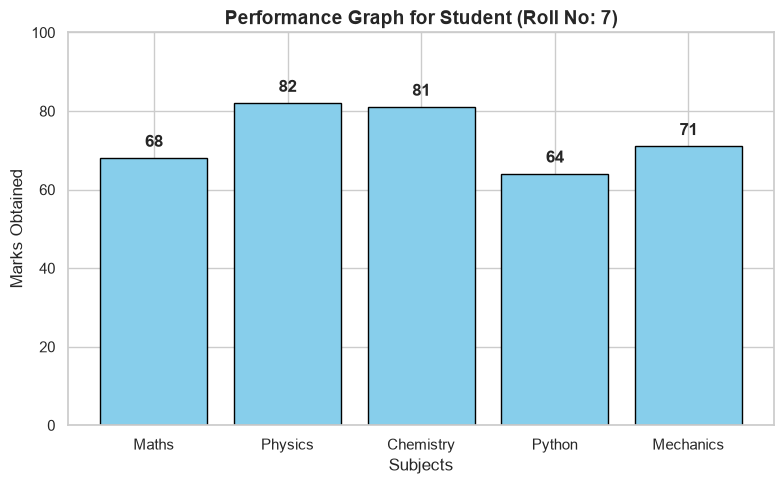



        STUDENT PERFORMANCE ANALYZER
1. Add Student
2. View All Students
3. Search Student
4. Delete Student
5. Class Statistics
6. Subject-wise Analysis
7. Visualize Performance Graphs
8. Individual Student Graphs
9. Save Analyzed Results
10. Exit



Enter your choice:  10



Thank you for using the program!


In [5]:
import pandas as pd
import os
import matplotlib.pyplot as plt
import seaborn as sns

# ---------------------------------
# STUDENT PERFORMANCE ANALYZER
# ---------------------------------

FILE_NAME = r"C:\Users\Priyal\OneDrive\Documents\python_mp_data.xlsx"
OUTPUT_FILE = "analyzed_results.xlsx"

SUBJECTS = [
    "Maths",
    "Physics",
    "Chemistry",
    "Python",
    "Mechanics"
]


# ---------------------------------
# 1. LOAD EXCEL FILE
# ---------------------------------

def load_data():
    if not os.path.exists(FILE_NAME):
        print("Excel file not found!")
        return None

    try:
        df = pd.read_excel(FILE_NAME)

        required_columns = ["Roll No"] + SUBJECTS

        for col in required_columns:
            if col not in df.columns:
                print("Missing column:", col)
                return None

        return df

    except Exception as e:
        print("Error loading file:", e)
        return None


# ---------------------------------
# 2. CALCULATE GRADE
# ---------------------------------

def calculate_grade(percentage):
    if percentage >= 90:
        return "A+"
    elif percentage >= 80:
        return "A"
    elif percentage >= 70:
        return "B"
    elif percentage >= 60:
        return "C"
    elif percentage >= 50:
        return "D"
    else:
        return "F"


# ---------------------------------
# 3. ANALYZE STUDENT MARKS
# ---------------------------------

def analyze_data(df):
    df = df.copy()

    df["Total"] = df[SUBJECTS].sum(axis=1)

    df["Percentage"] = (
        df["Total"] / (len(SUBJECTS) * 100)
    ) * 100

    df["Percentage"] = df["Percentage"].round(2)

    df["Grade"] = df["Percentage"].apply(
        calculate_grade
    )

    return df


# ---------------------------------
# 4. ADD STUDENT
# ---------------------------------

def add_student():
    df = load_data()

    if df is None:
        return

    roll = input("Enter Roll Number: ")

    if roll in df["Roll No"].astype(str).values:
        print("Roll number already exists!")
        return

    name = input("Enter Student Name: ")

    marks = {}

    for subject in SUBJECTS:
        while True:
            try:
                mark = float(
                    input(f"Enter marks in {subject}: ")
                )

                if 0 <= mark <= 100:
                    marks[subject] = mark
                    break
                else:
                    print("Marks must be between 0 and 100.")

            except ValueError:
                print("Enter a valid number.")

    new_student = {
        "Roll No": roll,
        "Name": name
    }

    new_student.update(marks)

    df = pd.concat(
        [df, pd.DataFrame([new_student])],
        ignore_index=True
    )

    df.to_excel(FILE_NAME, index=False)

    print("\nStudent added successfully!")


# ---------------------------------
# 5. VIEW ALL STUDENTS
# ---------------------------------

def view_students():
    df = load_data()

    if df is None:
        return

    df = analyze_data(df)

    print("\n========== ALL STUDENTS ==========")
    print(df.to_string(index=False))


# ---------------------------------
# 6. SEARCH STUDENT
# ---------------------------------

def search_student():
    df = load_data()

    if df is None:
        return

    roll = input("Enter Roll Number: ")

    result = df[
        df["Roll No"].astype(str) == roll
    ]

    if result.empty:
        print("Student not found!")
    else:
        result = analyze_data(result)
        print("\n========== STUDENT DETAILS ==========")
        print(result.to_string(index=False))


# ---------------------------------
# 7. DELETE STUDENT
# ---------------------------------

def delete_student():
    df = load_data()

    if df is None:
        return

    roll = input("Enter Roll Number to delete: ")

    if roll not in df["Roll No"].astype(str).values:
        print("Student not found!")
    else:
        df = df[
            df["Roll No"].astype(str) != roll
        ]

        df.to_excel(FILE_NAME, index=False)
        print("Student deleted successfully!")


# ---------------------------------
# 8. CLASS STATISTICS
# ---------------------------------

def class_statistics():
    df = load_data()

    if df is None or df.empty:
        print("No student records available!")
        return

    df = analyze_data(df)

    highest = df.loc[
        df["Percentage"].idxmax()
    ]

    lowest = df.loc[
        df["Percentage"].idxmin()
    ]

    average = df["Percentage"].mean()

    print("\n========== CLASS STATISTICS ==========")
    print("Total Students:", len(df))
    print(f"Class Average: {average:.2f}%")
    print(
        "Highest Performer:",
        highest["Roll No"],
        highest.get("Name", "N/A"),
        f"({highest['Percentage']}%)"
    )
    print(
        "Lowest Performer:",
        lowest["Roll No"],
        lowest.get("Name", "N/A"),
        f"({lowest['Percentage']}%)"
    )
    print(
        "Students Above Class Average:",
        (df["Percentage"] > average).sum()
    )
    print(
        "Students Below Class Average:",
        (df["Percentage"] < average).sum()
    )
    print("\nGrade Distribution:")
    print(df["Grade"].value_counts().sort_index())


# ---------------------------------
# 9. SUBJECT-WISE ANALYSIS
# ---------------------------------

def subject_analysis():
    df = load_data()

    if df is None or df.empty:
        print("No student records available!")
        return

    print("\n======= SUBJECT-WISE ANALYSIS =======")

    for subject in SUBJECTS:
        average = df[subject].mean()
        highest = df[subject].max()
        lowest = df[subject].min()

        print(f"\nSubject: {subject}")
        print(f"Average Marks: {average:.2f}")
        print(f"Highest Marks: {highest}")
        print(f"Lowest Marks: {lowest}")


# ---------------------------------
# 10. VISUALIZE PERFORMANCE
# ---------------------------------

def visualize_performance():
    df = load_data()

    if df is None or df.empty:
        print("No student records available to visualize!")
        return

    df = analyze_data(df)

    # Set up the visual style
    sns.set_theme(style="whitegrid")
    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # 1. Subject-wise Average Marks Bar Chart
    subject_avgs = [df[subj].mean() for subj in SUBJECTS]
    sns.barplot(x=SUBJECTS, y=subject_avgs, ax=axes[0], hue=SUBJECTS, palette="Blues_d", legend=False)
    axes[0].set_title("Average Marks per Subject", fontsize=14, fontweight="bold")
    axes[0].set_ylabel("Average Marks", fontsize=12)
    axes[0].set_ylim(0, 100)
    for i, v in enumerate(subject_avgs):
        axes[0].text(i, v + 2, f"{v:.1f}", ha='center', fontweight='bold')

    # 2. Grade Distribution Count Plot
    grade_order = ["A+", "A", "B", "C", "D", "F"]
    sns.countplot(x=df["Grade"], order=grade_order, ax=axes[1], hue=df["Grade"], palette="Set2", legend=False)
    axes[1].set_title("Class Grade Distribution", fontsize=14, fontweight="bold")
    axes[1].set_xlabel("Grades", fontsize=12)
    axes[1].set_ylabel("Number of Students", fontsize=12)

    plt.tight_layout()
    print("\nGenerating performance graphs...")
    plt.show()

# ---------------------------------
# 11. SAVE ANALYZED RESULTS
# ---------------------------------

def save_results():
    df = load_data()

    if df is None or df.empty:
        print("No student records available!")
        return

    df = analyze_data(df)

    df.to_excel(OUTPUT_FILE, index=False)

    print("\nAnalysis saved to:", OUTPUT_FILE)


    # ---------------------------------
# 11. INDIVIDUAL STUDENT GRAPH
# ---------------------------------

def individual_student_graph():
    df = load_data()

    if df is None or df.empty:
        print("No student records available!")
        return

    roll = input("Enter Roll Number to visualize: ")

    result = df[df["Roll No"].astype(str) == roll]

    if result.empty:
        print("Student not found!")
        return

    student_data = result.iloc[0]
    name = student_data.get("Name", "Student")

    # Extract marks for each subject
    marks = [student_data[subj] for subj in SUBJECTS]

    # Set up the plot
    plt.figure(figsize=(8, 5))
    sns.set_theme(style="whitegrid")

    bars = plt.bar(SUBJECTS, marks, color='skyblue', edgecolor='black')
    plt.title(f"Performance Graph for {name} (Roll No: {roll})", fontsize=14, fontweight="bold")
    plt.xlabel("Subjects", fontsize=12)
    plt.ylabel("Marks Obtained", fontsize=12)
    plt.ylim(0, 100)

    # Display the exact marks on top of each bar
    for bar in bars:
        height = bar.get_height()
        plt.text(
            bar.get_x() + bar.get_width() / 2., 
            height + 2, 
            f"{height}", 
            ha='center', 
            va='bottom', 
            fontweight='bold'
        )

    plt.tight_layout()
    print(f"\nGenerating performance graph for {name}...")
    plt.show()


# ---------------------------------
# 12. MAIN MENU
# ---------------------------------

def main():
    while True:
        print("\n")
        print("=" * 45)
        print("        STUDENT PERFORMANCE ANALYZER")
        print("=" * 45)
        print("1. Add Student")
        print("2. View All Students")
        print("3. Search Student")
        print("4. Delete Student")
        print("5. Class Statistics")
        print("6. Subject-wise Analysis")
        print("7. Visualize Performance Graphs")
        print("8. Individual Student Graphs")
        print("9. Save Analyzed Results")
        print("10. Exit")

        choice = input("\nEnter your choice: ")

        if choice == "1":
            add_student()
        elif choice == "2":
            view_students()
        elif choice == "3":
            search_student()
        elif choice == "4":
            delete_student()
        elif choice == "5":
            class_statistics()
        elif choice == "6":
            subject_analysis()
        elif choice == "7":
            visualize_performance()
        elif choice == "8":
            individual_student_graph()
        elif choice == "9":
            save_results()
        elif choice == "10":
            print("\nThank you for using the program!")
            break
        else:
            print("Invalid choice! Try again.")


# ---------------------------------
# RUN PROGRAM
# ---------------------------------

main()